[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pantrok/hidroxai-mx/blob/main/notebooks/tutoriales/03_entrenar_evaluar.ipynb)

# Tutorial 3 · Entrenar y evaluar pronósticos de gasto

**Objetivo.** armar ventanas de 30 días con partición cronológica y comparar persistencia, XGBoost y una red TCN pequeña en una cuenca (Alta del Balsas) a un día de anticipación, con NSE, KGE y skill score.

> **Las cifras de este tutorial son ilustrativas.** Usa una cuenca, una semilla, pocas épocas y una sola configuración por modelo. Los resultados del benchmark (91 estaciones, cuatro cuencas, tres horizontes, tres semillas, mallas de hiperparámetros) están en [`results/xai_benchmark/`](https://github.com/pantrok/hidroxai-mx/tree/xai-benchmark-v1.5/results/xai_benchmark).

*Proyecto IND-2026-0335 · Instituto Politécnico Nacional (IPN) · Convocatoria PICDT2026. Datos: CONAGUA (Sistema de Información Hidrológica), INEGI y HydroSHEDS.*

In [1]:
# En Colab instala la biblioteca desde GitHub; fuera de Colab usa la que ya esté instalada.
# Va sin dependencias porque Colab ya trae pandas, pyarrow, matplotlib, torch y xgboost.
import importlib.util
import subprocess
import sys

if "google.colab" in sys.modules and importlib.util.find_spec("hidroxai_mx") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps",
                    "git+https://github.com/pantrok/hidroxai-mx@main"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "captum"], check=True)

## 1. Datos de la cuenca

Se lee la tabla de características solo para las estaciones de la cuenca (la primera vez descarga unos 96 MB).

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hidroxai_mx import ejemplos as E
from hidroxai_mx.dataset import abrir_dataset, como_citar
from hidroxai_mx.models import data as D
from hidroxai_mx.models import nets as N
from hidroxai_mx.models import train as T
from hidroxai_mx.models import xgb as X

REDUCIDO = E.modo_reducido()           # modo rápido para la integración continua
ds = abrir_dataset()
claves = E.claves_cuenca(ds.vinculo_hidrorivers(), E.CUENCA)
if REDUCIDO:
    claves = claves[:3]
paneles = E.paneles(ds.tabla_caracteristicas(claves=claves), claves)
SEMILLA, EPOCAS = E.SEMILLAS[0], (1 if REDUCIDO else 3)
print(f"Cuenca {E.CUENCA}: {len(paneles)} estaciones")

Cuenca Alta del Balsas: 12 estaciones


## 2. Ventanas y partición cronológica

Cada muestra es una ventana de 30 días con 6 canales (gasto, medias móviles de 7 y 30 días, precipitación interpolada y el día del año como seno y coseno) y el objetivo es el gasto del día t + 1. Una muestra es válida si la ventana está completa, no tiene valores marcados (`calidad = 2`) y el objetivo es original (`calidad = 0`). La ventana completa y el día objetivo caen dentro de su periodo. Los canales de gasto y precipitación se transforman con log1p y se estandarizan por estación con los estadísticos del entrenamiento.

In [3]:
arr = D.group_arrays(paneles, h=1)
pd.DataFrame({p: {"inicio": D.PARTITIONS[p][0], "fin": D.PARTITIONS[p][1], "muestras": len(arr[p]["y"])}
              for p in D.PARTITIONS}).T

,inicio,fin,muestras
train,2010-01-01,2020-12-31,26739
val,2021-01-01,2022-12-31,7552
test,2023-01-01,2025-09-03,6710


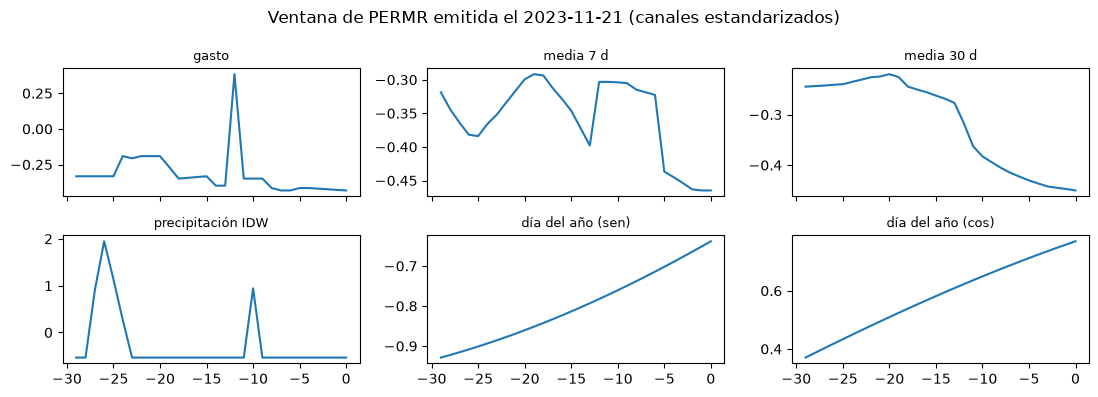

In [4]:
NOMBRES = ["gasto", "media 7 d", "media 30 d", "precipitación IDW",
           "día del año (sen)", "día del año (cos)"]
i = len(arr["test"]["y"]) // 2
x, info = arr["test"]["X"][i], arr["test"]["meta"].iloc[i]
fig, axes = plt.subplots(2, 3, figsize=(11, 4), sharex=True)
for j, ax in enumerate(axes.ravel()):
    ax.plot(range(-29, 1), x[:, j])
    ax.set_title(NOMBRES[j], fontsize=9)
fig.suptitle(f"Ventana de {info['clave']} emitida el {info['issue']:%Y-%m-%d} (canales estandarizados)")
plt.tight_layout()
plt.show()

## 3. Modelos

- **Persistencia:** el pronóstico es el gasto del día de emisión, Q(t).
- **XGBoost:** la ventana aplanada (180 columnas), profundidad 4, parada temprana en validación.
- **TCN:** red convolucional temporal de 32 canales, entrenada hasta 3 épocas (1 en el modo reducido) con parada temprana; se restauran los pesos de la mejor época.

In [5]:
tr, va, te = arr["train"], arr["val"], arr["test"]
booster = X.fit(tr["X"], tr["y"], va["X"], va["y"], max_depth=4, seed=SEMILLA)
pron_xgb = E.a_gasto(X.predict(booster, te["X"]), te["meta"], arr["scalers"])
print(f"XGBoost: {booster.best_iteration + 1} árboles")

XGBoost: 91 árboles


In [6]:
red = N.build("tcn", 32)
hist = T.fit(red, tr["X"], tr["y"], va["X"], va["y"], seed=SEMILLA, max_epochs=EPOCAS)
red.eval()
pron_tcn = E.a_gasto(T.predict(red, te["X"]), te["meta"], arr["scalers"])
print(f"TCN: {hist['epochs']} épocas; pérdida de validación por época: {np.round(hist['history'], 4)}")

TCN: 3 épocas; pérdida de validación por época: [0.3258 0.3211 0.3236]


## 4. Evaluación en el periodo de prueba (2023 – 3 sep 2025)

Por estación: NSE, KGE y skill score contra persistencia, SS = 1 − MSE(modelo)/MSE(persistencia). La tabla da la mediana entre estaciones.

In [7]:
tabla = E.tabla_metricas(te["meta"], {"xgboost": pron_xgb, "tcn": pron_tcn})
E.resumen_metricas(tabla).round(3)

,nse,kge,skill,estaciones
modelo,,,,
persistencia,0.187,0.575,0.000,12
xgboost,0.346,0.323,0.272,12
tcn,0.349,0.324,0.246,12


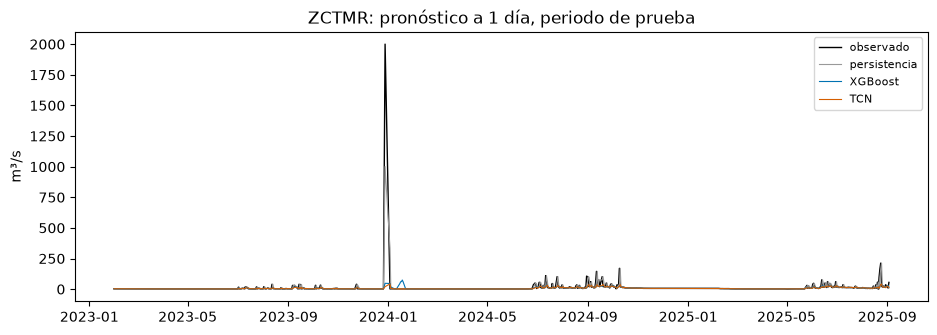

In [8]:
m = te["meta"]
clave = m["clave"].value_counts().idxmax()
s = (m["clave"] == clave).to_numpy()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(m.loc[s, "target_date"], m.loc[s, "y_flow"], color="k", lw=1, label="observado")
for nombre, p, color in [("persistencia", m["q_issue"].to_numpy(), "0.6"),
                         ("XGBoost", pron_xgb, "#0072B2"), ("TCN", pron_tcn, "#D55E00")]:
    ax.plot(m.loc[s, "target_date"], p[s], lw=0.8, color=color, label=nombre)
ax.set_ylabel("m³/s")
ax.set_title(f"{clave}: pronóstico a 1 día, periodo de prueba")
ax.legend(fontsize=8)
plt.show()

## 5. Comparación con el benchmark

Estas son las medianas publicadas para la misma cuenca y horizonte (archivo `rq1_summary.csv` del tag `xai-benchmark-v1.5`). Son la referencia; las de arriba solo ilustran el procedimiento.

In [9]:
bench = pd.read_csv("https://raw.githubusercontent.com/pantrok/hidroxai-mx/xai-benchmark-v1.5/results/xai_benchmark/rq1_summary.csv")
bench[(bench["grupo"] == E.CUENCA) & (bench["h"] == 1)][
    ["modelo", "estaciones", "nse_mediana", "kge_mediana", "ss_mediana"]].reset_index(drop=True)

,modelo,estaciones,nse_mediana,kge_mediana,ss_mediana
0,arima,12,0.3538,0.3891,0.2655
1,climatologia,12,-0.0466,-0.1487,-0.4442
2,convnext,12,0.3484,0.3350,0.2549
3,patchtst,12,0.3592,0.3737,0.2758
4,persistencia,12,0.1866,0.5745,0.0000
5,tcn,12,0.3452,0.3380,0.2582
6,xgboost,12,0.3503,0.3443,0.2768


## Cómo citar

Si usas estos datos, cita el artículo que describe el dataset (*Data in Brief*, 2026) y la versión del dataset que usaste. Las referencias salen de los metadatos de Crossref y de Zenodo.

In [10]:
print(como_citar())

Artículo de datos:
Sánchez-Ruiz, D., Reyes-Peña, C., Reyes-Cocoletzi, L., García-Ramírez, J., Ramos-Aguilar, E., & Ramos-Aguilar, R. (2026). Hidro-MX: daily hydroclimatic dataset for four pilot basins in Mexico from National Water Commission and National Institute of Statistics and Geography sources, with digital elevation models and station–river network links. Data in Brief, 69, 113442. https://doi.org/10.1016/j.dib.2026.113442

Dataset (v2026.11):
Sánchez-Ruiz, D., Ramos Aguilar, E., Ramos-Aguilar, R., Reyes-Peña, C., Reyes-Cocoletzi, L., & García-Ramírez, J. (2026). Hidro-MX v2026.11: a reproducible hydroclimatic dataset for Mexican pilot basins (CONAGUA-SIH and INEGI) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.24119292
Todas las versiones (DOI de concepto): https://doi.org/10.5281/zenodo.21231600

Créditos: Instituto Politécnico Nacional (IPN) · Convocatoria PICDT2026 · proyecto IND-2026-0335. Datos: CONAGUA (Sistema de Información Hidrológica), INEGI y HydroSHEDS.
